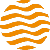

In [6]:
from IPython.display import Image, display
display(Image(filename='../../logos/gerics.png'))

![](../../docs/gerics.png)

# GERICS Climate factsheet Africa

## Code to plot the climate stripes 


*Climate stripes* have been established by Professor Ed Hawkins, Universität Reading in 2018.

The data base is ERA5 average over each African country.
Data source: "Hersbach, H, Bell, B, Berrisford, P, et al. The ERA5 global reanalysis. Q J R Meteorol Soc. 2020; 146: 1999– 2049. https://doi.org/10.1002/qj.3803". 

**Katharina Bülow**, Climate Service Center Germany (GERICS), Helmholtz-Zentrum hereon GmbH, Email: katharina.buelow@hereon.de


In [7]:
import os

import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import ListedColormap

In [8]:
import warnings
warnings.filterwarnings('ignore')

#### Organization of directories and input and output files

In [9]:
wkdir = os.getcwd()
datadir= wkdir.replace("ERA5", "data")
datadir = os.path.join(datadir, "spavg/spavg_era5")
file="climdexERA5_TG_year_weighted_means_update.csv"
inputT=os.path.join(datadir,file)

plotdir = wkdir.replace("Notebooks/ERA5", "PLOTS/ERA5-Plots-climatestripes")

if not os.path.exists(plotdir):
    os.makedirs(plotdir)


#### Select country:

In [11]:
# Country selection
#country = "Ivory Coast"
#country = "Togo"
country = "Burkina Faso"

region = country.replace(" ", "_")
plotname = "Climatestripes_deviation_to_1991_2020_ERA5_" + region+".png"
figure = os.path.join(plotdir, plotname)

In [12]:
def select_region(df, country):
    return df.loc[(df["region"].isin([country]))]

In [13]:
def deviation(df):
    df = df.copy()
    df["time"] = pd.to_datetime(df["time"], errors="coerce")
    df = df.dropna(subset=["time"]).copy()

    start = "1991-01-01"
    end = "2020-12-31"

    mask = (df["time"] >= start) & (df["time"] <= end)
    df_new = df[mask]

    if df_new.empty:
        raise ValueError("Keine Daten im Referenzzeitraum 1991-2020 gefunden.")

    hist = df_new["value"].mean()
    df["Temperature anomaly [°C]"] = df["value"] - hist

    # hübscher für die Graphik:
    df["year"] = df["time"].dt.year.astype(int)

    return df

In [15]:
# Unify time format in df to YYYY-MM-DD
df["time"] = pd.to_datetime(df["time"], errors="coerce")

n_invalid = df["time"].isna().sum()
if n_invalid > 0:
    print(f"Warning: {n_invalid} invalid time values found.")

df = df.dropna(subset=["time"]).copy()
df["time"] = df["time"].dt.strftime("%Y-%m-%d")

df.tail()

,realization,time,region,value,ci_name,ci_frequency,ci_package_name,ci_package_reference,standard_name,units
4670,<NA>_GERICS_<NA>_<NA>_<NA>_unknown_year_TG,2025-07-15,Bir Tawil,301.37994,TG,year,xclim_0.61.1,xcalc_1000.dev737+gef63188c3,air_temperature,K
4671,<NA>_GERICS_<NA>_<NA>_<NA>_unknown_year_TG,2025-07-15,Madagascar,296.27118,TG,year,xclim_0.61.1,xcalc_1000.dev737+gef63188c3,air_temperature,K
4672,<NA>_GERICS_<NA>_<NA>_<NA>_unknown_year_TG,2025-07-15,Comoros,298.94620,TG,year,xclim_0.61.1,xcalc_1000.dev737+gef63188c3,air_temperature,K
4673,<NA>_GERICS_<NA>_<NA>_<NA>_unknown_year_TG,2025-07-15,São Tomé and Principe,299.09730,TG,year,xclim_0.61.1,xcalc_1000.dev737+gef63188c3,air_temperature,K
4674,<NA>_GERICS_<NA>_<NA>_<NA>_unknown_year_TG,2025-07-15,Cabo Verde,296.36510,TG,year,xclim_0.61.1,xcalc_1000.dev737+gef63188c3,air_temperature,K


In [16]:
# Read ERA5 data and calculate deviations:
df = pd.read_csv(inputT)
dfr = select_region(df, country)
dfn = deviation(dfr)

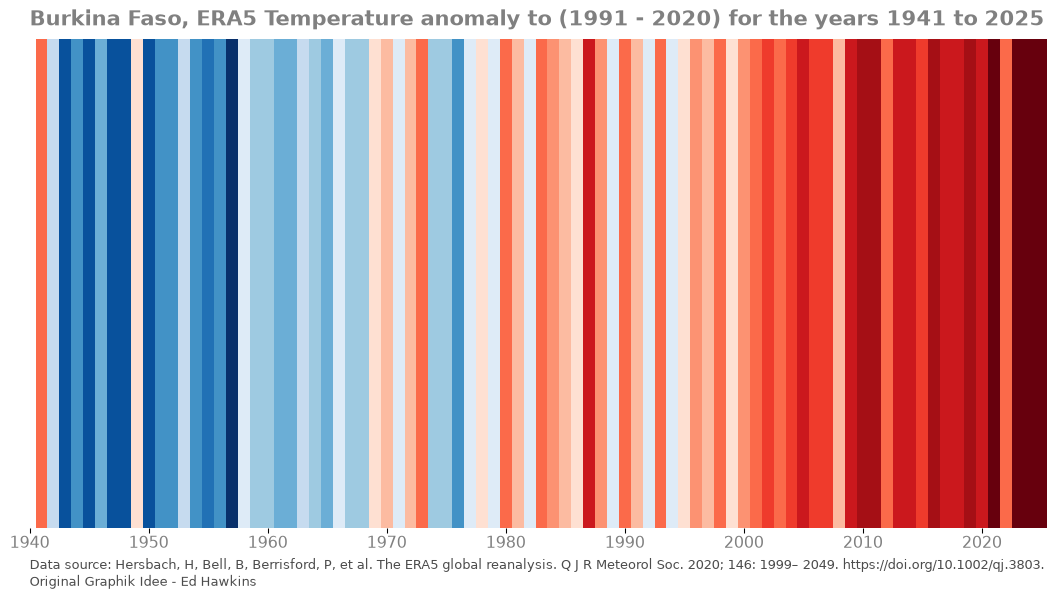

In [18]:
# Create Figure:
#
# SOURCE:
# plotting routine: https://towardsdatascience.com/visualizing-climate-change-a-step-by-step-guide-to-reproduce-climate-stripes-with-python-ea1d440e8e8d

dfn = dfn.copy()
dfn["year"] = pd.to_numeric(dfn["year"], errors="coerce")
dfn = dfn.dropna(subset=["year", "Temperature anomaly [°C]"]).copy()
dfn["year"] = dfn["year"].astype(int)
y0 = int(dfn["year"].min())
y1 = int(dfn["year"].max())

fig, ax = plt.subplots(figsize=(13.33, 7.5), dpi=96)

# Farben - 8 blau und 8 rot
cmap = ListedColormap(
    [
        "#08306b",
        "#08519c",
        "#2171b5",
        "#4292c6",
        "#6baed6",
        "#9ecae1",
        "#c6dbef",
        "#deebf7",
        "#fee0d2",
        "#fcbba1",
        "#fc9272",
        "#fb6a4a",
        "#ef3b2c",
        "#cb181d",
        "#a50f15",
        "#67000d",
    ]
)

# lineare Normalizirung der Daten in das [0.0, 1.0] Interval
norm = mpl.colors.Normalize(
    dfn["Temperature anomaly [°C]"].min(), dfn["Temperature anomaly [°C]"].max()
)

# Darstellen der Balken
bar = ax.bar(
    dfn["year"],
    1,
    color=cmap(norm(dfn["Temperature anomaly [°C]"])),
    width=1,
    zorder=2,
)

# Entfernen der *spines*
ax.spines[["top", "left", "bottom", "right"]].set_visible(False)

# Format für y-axis label and tick labels
ax.set_ylabel("", fontsize=12, labelpad=10)
ax.set_yticks([])
ax.set_ylim([0, 1])

# Format für x-axis label and tick labels
ax.set_xlabel("", fontsize=12, labelpad=10)
ax.xaxis.set_tick_params(
    pad=2,
    labelbottom=True,
    bottom=True,
    labelsize=12,
    labelrotation=0,
    labelcolor="grey",
)
ax.set_xlim([dfn["year"].min() - 1, dfn["year"].max() + 1])

# Titel eingeben:
ax.set_title(
    country + f", ERA5 Temperature anomaly to (1991 - 2020) for the years {y0} to {y1}",
    loc="left",
    color="grey",
    fontweight="bold",
    size=16,
    pad=10,
)

# Datenquelle: Text eingeben
ax.text(
    x=0.1,
    y=0.12,
    s="Data source: Hersbach, H, Bell, B, Berrisford, P, et al. The ERA5 global reanalysis. Q J R Meteorol Soc. 2020; 146: 1999– 2049. https://doi.org/10.1002/qj.3803. \nOriginal Graphik Idee - Ed Hawkins",

    transform=fig.transFigure,
    ha="left",
    fontsize=10,
    alpha=0.7,
)

# Anpassen der Ränder und Abstände
plt.subplots_adjust(
    left=0.1, right=None, top=None, bottom=0.2, wspace=None, hspace=None
)

# Weißer Hintergrund
fig.patch.set_facecolor("white")
ax.patch.set_facecolor("white")
plt.savefig(figure, dpi=1200)